# PlantSR · Denoising and Colorization — Pretrained vs. Fine-tuned
AAI 521 Group 1 · Owner: Jinyuan He · Google Colab · **GPU runtime** (T4 or better)

This notebook fine-tunes two pretrained restoration models on the PlantSR training split. It then compares them with their original pretrained checkpoints and with simple baselines on identical held-out inputs.

| Task | Pretrained model | Simple baselines | Fine-tuning |
| --- | --- | --- | --- |
| Denoising | [Restormer](https://huggingface.co/deepinv/Restormer), blind Gaussian colour denoising (`gaussian_color_denoising_blind.pth`) | Noisy input; OpenCV non-local means, tuned on validation | L1 on random 256×256 crops with σ ∈ [5, 25] |
| Colorization | [DDColor tiny](https://huggingface.co/piddnad/ddcolor_paper_tiny) (ConvNeXt-T, Apache-2.0) | Grayscale repeated as RGB (weak baseline) | L1 on Lab *ab* + 0.1 × LPIPS-VGG on random 256×256 crops |

**Protocol** (follows the README evaluation rules):
1. Use the frozen `train/val/test` manifests from the prepared dataset on Google Drive.
2. Train on random 256×256 crops of full-size training images. Validate and test on the saved 256×256 centre crops.
3. Use fixed validation and test degradations, seeded per sample. Denoising uses σ = 15 as the primary test level and σ = 5 and 25 as robustness sets. Colorization uses fixed Lab-L* grayscale. The inputs are saved as PNGs so teammates and the app can reuse them.
4. Select the checkpoint on **validation** only: PSNR at σ = 15 for denoising and mean CIEDE2000 for colorization. The test set is evaluated once, after training.
5. Report per-image metrics in the shared long format, mean ± 95% CI, and paired fine-tuned-vs-pretrained statistics. Include visual grids that contain a worst-case failure.

**Outputs** are saved to `OUT_DIR` on Google Drive: checkpoints, training logs, fixed evaluation inputs, per-image metrics, summary tables and figures. Training **resumes automatically** if the Colab session disconnects; rerun all cells.

**Two ways to run:**
- **Colab web UI:** upload this notebook, choose a GPU runtime and run all cells.
- **Colab CLI from your terminal:** run `scripts/colab_run_denoise_colorize.sh`; see that script's header.

Run the cells from top to bottom. Set `QUICK_TRIAL = True` (or `PLANTSR_QUICK_TRIAL=1` with the CLI) first to run the 100-step check from README §6. It checks for finite losses and parameter updates and reloads the checkpoint.

## 1 · Install dependencies and check the GPU

Colab already provides `torch`, `torchvision`, `numpy`, `scipy`, `scikit-image`, `opencv` and `pandas`. This cell adds pinned versions of:
- `spandrel` and `spandrel_extra_arches`, which provide the Restormer and DDColor architectures
- `lpips` for perceptual similarity
- `kornia` for differentiable sRGB↔Lab conversion

In [1]:
# Install the pinned model/metric libraries and report the GPU.
import subprocess
import sys

subprocess.run(
    [sys.executable, "-m", "pip", "install", "--quiet",
     "spandrel==0.4.2", "spandrel_extra_arches==0.2.0", "lpips==0.1.4", "kornia==0.9.1", "gdown"],
    check=True,
)

import torch

print("torch", torch.__version__)
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} · {props.total_memory / 2**30:.1f} GiB")
else:
    print("No GPU detected — use Runtime > Change runtime type > GPU. CPU is far too slow for fine-tuning.")

torch 2.14.1+cu130
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition · 95.0 GiB


## 2 · Mount Google Drive and configure the experiment

The notebook looks for the prepared dataset in the following order. It uses the first match:
1. A folder that contains `manifests/train.csv`, from `DATA_DIR_CANDIDATES`. For example, this is the output folder of the preprocessing notebook.
2. The ZIP file `PlantSR_prepared_for_team.zip`, from `DATA_ZIP_CANDIDATES`. It is extracted once to the Colab local disk.
3. If neither exists, the team's shared ZIP from the README link is downloaded to the first `DATA_ZIP_CANDIDATES` path on your Drive.

Edit these paths if your Drive layout differs.

**Batch size and VRAM.** The batch size is chosen from the available VRAM. If you see `CUDA out of memory`, halve `batch` and double `grad_accum`. This keeps the effective batch size the same.

In [2]:
# Mount Drive and define all paths, seeds and training settings in one place.
import os
import json
import math
import time
import hashlib
import shutil
import zipfile
from pathlib import Path

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")   # with the Colab CLI, run `colab drivemount -s <session>` beforehand instead


def env_flag(name, default):
    return os.environ.get(name, str(int(default))).strip().lower() in {"1", "true", "yes"}

PROJECT_DIR = Path(os.environ.get("PLANTSR_PROJECT_DIR", "/content/drive/MyDrive/AAI521/Final_project"))
DATA_DIR_CANDIDATES = [
    PROJECT_DIR / "PlantSR_prepared_opaque_v2",
    PROJECT_DIR / "prepared",
    PROJECT_DIR / "PlantSR_prepared_for_team" / "prepared",
]
DATA_ZIP_CANDIDATES = [
    PROJECT_DIR / "PlantSR_prepared_for_team.zip",
    Path("/content/drive/MyDrive/PlantSR_prepared_for_team.zip"),
]
DATA_ZIP_DRIVE_ID = "1j_vx9Yuow1pu8MzYmbGY4udXBpB4dBx1"   # README download link; set "" to disable auto-download
LOCAL_EXTRACT_DIR = Path(os.environ.get("PLANTSR_LOCAL_DIR", "/content/plantsr_data"))
OUT_DIR = PROJECT_DIR / "experiments" / "denoise_colorize"

# Each setting can be overridden from the Colab CLI, e.g. `colab exec ... --env PLANTSR_QUICK_TRIAL=1`.
RUN_TAG = os.environ.get("PLANTSR_RUN_TAG", "v1")   # change to start a new, separate run (old runs are kept)
SEED = 42
RUN_DENOISE = env_flag("PLANTSR_RUN_DENOISE", True)
RUN_COLORIZE = env_flag("PLANTSR_RUN_COLORIZE", True)
QUICK_TRIAL = env_flag("PLANTSR_QUICK_TRIAL", False)   # True → 100 steps per task to verify the pipeline

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 2**30 if DEVICE.type == "cuda" else 0.0
BF16_OK = DEVICE.type == "cuda" and torch.cuda.is_bf16_supported(including_emulation=False)

DENOISE_CFG = dict(
    weights_repo="deepinv/Restormer",
    weights_file="gaussian_color_denoising_blind.pth",
    train_sigma=(5.0, 25.0),        # 0–255 units, sampled uniformly per crop
    test_sigmas=(15, 5, 25),        # first entry is the primary level used for checkpoint selection
    crop=256,
    steps=4000,
    lr=3e-5,
    warmup=100,
    weight_decay=0.0,
    grad_clip=0.5,
    batch=2 if VRAM_GB < 20 else (4 if VRAM_GB < 35 else 8),
    grad_accum=2 if VRAM_GB < 20 else 1,
    val_every=500,
    log_every=25,
    nlm_h_factors=(0.6, 0.8, 1.0, 1.2, 1.4),   # NLM h = factor × σ, chosen on validation
)
COLOR_CFG = dict(
    weights_repo="piddnad/ddcolor_paper_tiny",
    weights_file="pytorch_model.bin",
    input_size=512,                 # official DDColor inference size; crops are resized to this and back
    crop=256,
    steps=3000,
    lr=2e-5,
    warmup=100,
    weight_decay=0.0,
    grad_clip=1.0,
    perceptual_weight=0.1,          # LPIPS-VGG weight (evaluation uses LPIPS-Alex)
    batch=4 if VRAM_GB < 35 else 8,
    grad_accum=1,
    val_every=500,
    log_every=25,
)
if QUICK_TRIAL:
    RUN_TAG += "_trial"
    for cfg in (DENOISE_CFG, COLOR_CFG):
        cfg.update(steps=100, val_every=50, log_every=10, warmup=10)

OUT_DIR.mkdir(parents=True, exist_ok=True)
EVAL_INPUT_DIR = OUT_DIR / "eval_inputs"
print(f"Device: {DEVICE} · VRAM {VRAM_GB:.1f} GiB · bf16 {BF16_OK}")
print(f"Outputs → {OUT_DIR} (run tag {RUN_TAG!r})")

Mounted at /content/drive
Device: cuda · VRAM 95.0 GiB · bf16 True
Outputs → /content/drive/MyDrive/AAI521/Final_project/experiments/denoise_colorize (run tag 'v1')


## 3 · Locate the prepared dataset and load the splits

This cell:
- reads the frozen manifests
- checks that every referenced file exists
- confirms that no duplicate group (`group_id`) crosses splits
- loads the data into memory

Full-size training images are kept in RAM, about 4 GB, so crops can be sampled quickly. The 256×256 validation and test centre crops are loaded as arrays.

In [3]:
# Find the prepared dataset, validate the manifests and load the images into memory.
import numpy as np
import pandas as pd
from PIL import Image


def find_data_root():
    for folder in DATA_DIR_CANDIDATES:
        if (folder / "manifests" / "train.csv").is_file():
            return folder
    if DATA_ZIP_DRIVE_ID and not any(z.is_file() for z in DATA_ZIP_CANDIDATES):
        # Fall back to the team's shared ZIP (README §5); saved on your Drive so later sessions reuse it.
        import gdown
        DATA_ZIP_CANDIDATES[0].parent.mkdir(parents=True, exist_ok=True)
        print(f"Downloading the shared prepared dataset → {DATA_ZIP_CANDIDATES[0]} …")
        gdown.download(id=DATA_ZIP_DRIVE_ID, output=str(DATA_ZIP_CANDIDATES[0]), quiet=True)
    for archive in DATA_ZIP_CANDIDATES:
        if archive.is_file():
            marker = LOCAL_EXTRACT_DIR / ".extracted"
            if not marker.exists():
                print(f"Extracting {archive} → {LOCAL_EXTRACT_DIR} …")
                LOCAL_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
                with zipfile.ZipFile(archive) as zf:
                    zf.extractall(LOCAL_EXTRACT_DIR)
                marker.touch()
            hits = sorted(LOCAL_EXTRACT_DIR.rglob("manifests/train.csv"))
            if hits:
                return hits[0].parent.parent
    raise FileNotFoundError(
        "Prepared dataset not found. Put the extracted `prepared/` folder or PlantSR_prepared_for_team.zip "
        f"on Drive and add its path to DATA_DIR_CANDIDATES / DATA_ZIP_CANDIDATES. Looked in: "
        f"{[str(p) for p in DATA_DIR_CANDIDATES + DATA_ZIP_CANDIDATES]}"
    )


DATA_ROOT = find_data_root()
MANIFESTS = {s: pd.read_csv(DATA_ROOT / "manifests" / f"{s}.csv") for s in ("train", "val", "test")}

groups = {s: set(df["group_id"]) for s, df in MANIFESTS.items()}
assert not (groups["train"] & groups["val"] or groups["train"] & groups["test"] or groups["val"] & groups["test"]), \
    "A duplicate group appears in more than one split — the manifests are inconsistent."
for split, df in MANIFESTS.items():
    column = "hr_path" if split == "train" else "eval_crop_path"
    missing = [p for p in df[column] if not (DATA_ROOT / p).is_file()]
    if missing:
        raise FileNotFoundError(f"{len(missing)} {split} files are missing, e.g. {missing[:3]}")
print(f"Dataset root: {DATA_ROOT}")
print({s: len(df) for s, df in MANIFESTS.items()})


def read_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB"), dtype=np.uint8)


t0 = time.time()
TRAIN_IMAGES = [read_rgb(DATA_ROOT / p) for p in MANIFESTS["train"]["hr_path"]]
print(f"Loaded {len(TRAIN_IMAGES)} full-size training images "
      f"({sum(a.nbytes for a in TRAIN_IMAGES) / 2**30:.2f} GiB) in {time.time() - t0:.0f}s")

CROPS = {}
for split in ("val", "test"):
    df = MANIFESTS[split].sort_values("sample_id").reset_index(drop=True)
    arr = np.stack([read_rgb(DATA_ROOT / p) for p in df["eval_crop_path"]])
    assert arr.shape[1:] == (256, 256, 3), f"Unexpected {split} crop shape {arr.shape}"
    CROPS[split] = (df["sample_id"].tolist(), arr)
    print(f"{split}: {arr.shape[0]} centre crops of {arr.shape[1]}×{arr.shape[2]}")

Extracting /content/drive/MyDrive/AAI521/Final_project/PlantSR_prepared_for_team.zip → /content/plantsr_data …
Dataset root: /content/plantsr_data/prepared
{'train': 663, 'val': 166, 'test': 200}
Loaded 663 full-size training images (3.04 GiB) in 22s
val: 166 centre crops of 256×256
test: 200 centre crops of 256×256


## 4 · Shared helpers: degradations, metrics and result logging

The helpers in this cell use these conventions:
- **Convention:** RGB images are `uint8` arrays in `[0, 255]`. Model tensors are `float` values in `[0, 1]`, shaped `N×3×H×W`. Every model output is rounded to `uint8` before scoring, which matches the saved PNG.
- **Noise:** the noise is `clip(round(clean + N(0, σ²)))`, in 0–255 units. Fixed sets seed each sample with `sha256(sample_id, σ, SEED)`, so the same noise is reproduced in every session.
- **Grayscale:** each pixel is set to the CIE L\* of the colour crop with a\* = b\* = 0, then converted back to sRGB with R = G = B. Colour models therefore receive the exact reference lightness, and the metrics measure only the predicted colour.
- **Metrics:**
  - PSNR and SSIM on the full 256×256 crop. These are standard RGB metrics; PSNR uses peak 255 and SSIM is computed per channel.
  - LPIPS-Alex.
  - GMS, a gradient-magnitude similarity that is a proxy for leaf-vein and edge preservation; higher is better.
  - Colorization only: CIEDE2000 ΔE₀₀, where lower is better.
  - Colorization only: colourfulness gap, the Hasler–Süsstrunk colourfulness of the output minus the reference. A negative gap means the output is desaturated.

In [4]:
# Degradations, tensor conversions, metrics and the long-format results writer.
import random
import kornia
import lpips
import torch.nn.functional as F
from scipy.ndimage import convolve
from skimage.color import rgb2lab, deltaE_ciede2000
from skimage.metrics import peak_signal_noise_ratio, structural_similarity


def stable_seed(*parts):
    return int.from_bytes(hashlib.sha256("|".join(map(str, parts)).encode()).digest()[:8], "little") % 2**32


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def to_tensor(arr_u8):
    arr = np.ascontiguousarray(arr_u8[None] if arr_u8.ndim == 3 else arr_u8)
    if not arr.flags.writeable:
        arr = arr.copy()
    return torch.from_numpy(arr).permute(0, 3, 1, 2).float().div(255).to(DEVICE)


def to_uint8(t):
    return t.detach().float().clamp(0, 1).mul(255).round().byte().permute(0, 2, 3, 1).cpu().numpy()


def quantize(t):
    return t.clamp(0, 1).mul(255).round().div(255)


def add_noise_fixed(clean_u8, sigma, key):
    rng = np.random.default_rng(stable_seed("noise", key, sigma, SEED))
    noisy = clean_u8.astype(np.float32) + rng.normal(0.0, sigma, clean_u8.shape).astype(np.float32)
    return np.clip(np.round(noisy), 0, 255).astype(np.uint8)


def gray_from_rgb(x):
    # x: float N×3×H×W sRGB → neutral gray with the same CIE L*, still 3 channels.
    lightness = kornia.color.rgb_to_lab(x)[:, :1]
    zeros = torch.zeros_like(lightness)
    return kornia.color.lab_to_rgb(torch.cat([lightness, zeros, zeros], 1), clip=True)


def to_gray_u8(rgb_u8):
    out = []
    for i in range(0, len(rgb_u8), 32):
        out.append(to_uint8(gray_from_rgb(to_tensor(rgb_u8[i:i + 32]))))
    gray = np.concatenate(out)
    return np.repeat(gray.mean(axis=3, keepdims=True).round().astype(np.uint8), 3, axis=3)


LPIPS_ALEX = lpips.LPIPS(net="alex", verbose=False).to(DEVICE).eval()
for p in LPIPS_ALEX.parameters():
    p.requires_grad_(False)


@torch.no_grad()
def lpips_scores(out_u8, ref_u8, batch=16):
    scores = []
    for i in range(0, len(out_u8), batch):
        a = to_tensor(out_u8[i:i + batch]) * 2 - 1
        b = to_tensor(ref_u8[i:i + batch]) * 2 - 1
        scores.append(LPIPS_ALEX(a, b).flatten().cpu().numpy())
    return np.concatenate(scores)


_PREWITT_X = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype=np.float64) / 3.0


def gms(out_u8, ref_u8, c=0.0026):
    def grad_mag(img):
        y = (img.astype(np.float64) / 255.0) @ np.array([0.299, 0.587, 0.114])
        return np.hypot(convolve(y, _PREWITT_X, mode="nearest"), convolve(y, _PREWITT_X.T, mode="nearest"))
    g1, g2 = grad_mag(out_u8), grad_mag(ref_u8)
    return float(np.mean((2 * g1 * g2 + c) / (g1 ** 2 + g2 ** 2 + c)))


def colorfulness(img_u8):
    r, g, b = (img_u8[..., i].astype(np.float64) for i in range(3))
    rg, yb = r - g, 0.5 * (r + g) - b
    return float(np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean()))


def image_metrics(out_u8, ref_u8, colour=False):
    m = {
        "psnr": float(peak_signal_noise_ratio(ref_u8, out_u8, data_range=255)),
        "ssim": float(structural_similarity(ref_u8, out_u8, channel_axis=2, data_range=255)),
        "gms": gms(out_u8, ref_u8),
    }
    if colour:
        m["deltaE00"] = float(deltaE_ciede2000(rgb2lab(ref_u8), rgb2lab(out_u8)).mean())
        m["colorfulness_gap"] = colorfulness(out_u8) - colorfulness(ref_u8)
    return m


HIGHER_IS_BETTER = {"psnr": True, "ssim": True, "gms": True, "lpips": False, "deltaE00": False,
                    "colorfulness_gap": None}
RESULT_FIELDS = ["sample_id", "task", "condition", "method", "checkpoint_revision", "seed", "metric_name",
                 "metric_value", "inference_seconds", "status", "error_note"]


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def evaluate_method(task, condition, method, revision, fn, ids, inputs_u8, refs_u8, colour=False):
    # Runs fn one image at a time (timed), then scores every output; returns long-format rows and outputs.
    rows, outputs, seconds, status = [], [], [], []
    for i in range(min(2, len(inputs_u8))):    # warm-up so timings exclude CUDA initialisation
        fn(inputs_u8[i:i + 1])
    for i, sid in enumerate(ids):
        try:
            sync()
            t0 = time.perf_counter()
            out = fn(inputs_u8[i:i + 1])[0]
            sync()
            seconds.append(time.perf_counter() - t0)
            outputs.append(out)
            status.append(("ok", ""))
        except Exception as exc:  # report failures rather than silently dropping them
            seconds.append(float("nan"))
            outputs.append(np.zeros_like(refs_u8[i]))
            status.append(("error", repr(exc)[:200]))
    outputs = np.stack(outputs)
    lp = lpips_scores(outputs, refs_u8)
    for i, sid in enumerate(ids):
        ok, note = status[i]
        metrics = image_metrics(outputs[i], refs_u8[i], colour) if ok == "ok" else {}
        metrics["lpips"] = float(lp[i]) if ok == "ok" else float("nan")
        for name, value in metrics.items():
            rows.append(dict(sample_id=sid, task=task, condition=condition, method=method,
                             checkpoint_revision=revision, seed=SEED, metric_name=name, metric_value=value,
                             inference_seconds=seconds[i], status=ok, error_note=note))
    return rows, outputs


def save_pngs(arr_u8, ids, folder):
    folder.mkdir(parents=True, exist_ok=True)
    for sid, img in zip(ids, arr_u8):
        Image.fromarray(img).save(folder / f"{sid}.png")


print("Helpers ready.")

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:00<00:00, 258MB/s] 


Helpers ready.


## 5 · Build the fixed validation and test inputs

This cell regenerates the noisy and grayscale inputs deterministically, so every session sees identical inputs. On the first run, it also saves them as PNGs together with a manifest in the shared README format, under `OUT_DIR/eval_inputs/`. Teammates and the web app can reuse the same benchmark inputs.

In [5]:
# Generate the fixed noisy/grayscale inputs and save them once (PNG + manifest) for reuse.
EVAL_INPUTS = {}   # (task, condition, split) → uint8 array aligned with CROPS[split][0]
manifest_rows = []
for split in ("val", "test"):
    ids, clean = CROPS[split]
    crop_info = MANIFESTS[split].set_index("sample_id")
    for sigma in DENOISE_CFG["test_sigmas"]:
        EVAL_INPUTS[("denoise", f"sigma{sigma}", split)] = np.stack(
            [add_noise_fixed(img, sigma, sid) for sid, img in zip(ids, clean)])
    EVAL_INPUTS[("colorize", "gray_lab_L", split)] = to_gray_u8(clean)
    for (task, cond, sp), arr in EVAL_INPUTS.items():
        if sp != split:
            continue
        folder = EVAL_INPUT_DIR / task / cond / split
        if not folder.is_dir() or len(list(folder.glob("*.png"))) != len(ids):
            save_pngs(arr, ids, folder)
        for sid in ids:
            r = crop_info.loc[sid]
            manifest_rows.append(dict(
                sample_id=sid, source_image_id=sid, split=split, task=task,
                input_path=str((folder / f"{sid}.png").relative_to(OUT_DIR)),
                target_path=str(Path(r["eval_crop_path"])), mask_path="",
                crop_coordinates=f"{r['crop_x']},{r['crop_y']},{r['crop_width']},{r['crop_height']}",
                degradation_parameters=(f"gaussian_sigma={cond[5:]};clip_round_uint8" if task == "denoise"
                                        else "cie_lab_L_only;a=b=0;srgb_d65"),
                seed=stable_seed("noise", sid, cond[5:], SEED) if task == "denoise" else ""))
pd.DataFrame(manifest_rows).to_csv(EVAL_INPUT_DIR / "eval_inputs_manifest.csv", index=False)

for key, arr in EVAL_INPUTS.items():
    print(key, arr.shape)

('denoise', 'sigma15', 'val') (166, 256, 256, 3)
('denoise', 'sigma5', 'val') (166, 256, 256, 3)
('denoise', 'sigma25', 'val') (166, 256, 256, 3)
('colorize', 'gray_lab_L', 'val') (166, 256, 256, 3)
('denoise', 'sigma15', 'test') (200, 256, 256, 3)
('denoise', 'sigma5', 'test') (200, 256, 256, 3)
('denoise', 'sigma25', 'test') (200, 256, 256, 3)
('colorize', 'gray_lab_L', 'test') (200, 256, 256, 3)


## 6 · Model loading, inference wrappers and the shared training loop

- Both checkpoints are downloaded from Hugging Face, and their resolved commit SHAs are recorded. The architectures are rebuilt by `spandrel` from the original state dicts.
- Fine-tuned weights are saved **in the same state-dict format** as the originals, so `spandrel` can reload them without this notebook. Restormer is saved as `{"params": ...}`; DDColor is saved as a plain state dict.
- **DDColor wrapper:** this follows the official pipeline.
  1. The gray crop is resized to 512 and the model predicts the *ab* channels.
  2. The *ab* channels are resized back and combined with the input's own L\*.
- **Training loop:**
  - AdamW with linear warm-up, then cosine decay.
  - Mixed precision: fp16 for Restormer on a T4; bf16 when the GPU supports it. DDColor runs in fp32 on a T4.
  - Gradient clipping.
  - A finite-loss guard.
  - Validation every `val_every` steps. Step 0 is the pretrained model.
  - Best-checkpoint selection on validation.
  - The full training state is saved, so a disconnected session resumes where it stopped.

In [6]:
# Load models via spandrel, define the inference wrappers, and the resumable training loop.
import spandrel_extra_arches
from huggingface_hub import hf_hub_download
from spandrel import ModelLoader

spandrel_extra_arches.install()


def download_weights(repo, filename):
    path = hf_hub_download(repo_id=repo, filename=filename)
    revision = Path(path).parent.name   # …/snapshots/<commit sha>/<file>
    return path, f"{repo}@{revision[:12]}"


def load_spandrel(path, expected_arch):
    state = torch.load(path, map_location="cpu", weights_only=True)
    state = state.get("params", state)
    descriptor = ModelLoader().load_from_state_dict(state)
    assert descriptor.architecture.name == expected_arch, descriptor.architecture.name
    return descriptor.model.to(DEVICE).eval()


def autocast_ctx(allow_fp16):
    if DEVICE.type != "cuda":
        return torch.autocast("cpu", enabled=False)
    if BF16_OK:
        return torch.autocast("cuda", dtype=torch.bfloat16)
    return torch.autocast("cuda", dtype=torch.float16, enabled=allow_fp16)


def pad_to_multiple(x, multiple=8):
    h, w = x.shape[-2:]
    ph, pw = (-h) % multiple, (-w) % multiple
    return (F.pad(x, (0, pw, 0, ph), mode="reflect") if ph or pw else x), (h, w)


@torch.no_grad()
def run_denoiser(model, noisy_u8, batch=8):
    model.eval()
    outs = []
    for i in range(0, len(noisy_u8), batch):
        x, (h, w) = pad_to_multiple(to_tensor(noisy_u8[i:i + batch]))
        with autocast_ctx(allow_fp16=True):
            y = model(x)
        outs.append(to_uint8(y[..., :h, :w]))
    return np.concatenate(outs)


def no_autocast():
    return torch.autocast(DEVICE.type, enabled=False)


def ddcolor_forward(model, gray, input_size):
    # gray: float N×3×H×W neutral image. Returns the input L* and predicted ab at H×W.
    with no_autocast():   # colour-space conversions always in fp32
        lightness = kornia.color.rgb_to_lab(gray.float())[:, :1]
    x = F.interpolate(gray, size=(input_size, input_size), mode="bilinear", align_corners=False)
    with autocast_ctx(allow_fp16=False):   # DDColor is not fp16-safe; bf16 or fp32 only
        ab = model(x)
    ab = F.interpolate(ab.float(), size=gray.shape[-2:], mode="bilinear", align_corners=False)
    return lightness, ab


def lab_to_rgb(lightness, ab):
    return kornia.color.lab_to_rgb(torch.cat([lightness, ab], 1), clip=True)


@torch.no_grad()
def run_colorizer(model, gray_u8, input_size, batch=8):
    model.eval()
    outs = []
    for i in range(0, len(gray_u8), batch):
        lightness, ab = ddcolor_forward(model, to_tensor(gray_u8[i:i + batch]), input_size)
        outs.append(to_uint8(lab_to_rgb(lightness, ab)))
    return np.concatenate(outs)


def random_train_crops(rng, n, size):
    batch = np.empty((n, size, size, 3), dtype=np.uint8)
    for k in range(n):
        img = TRAIN_IMAGES[rng.integers(len(TRAIN_IMAGES))]
        y = rng.integers(img.shape[0] - size + 1)
        x = rng.integers(img.shape[1] - size + 1)
        crop = img[y:y + size, x:x + size]
        crop = np.rot90(crop, k=int(rng.integers(4)))
        batch[k] = crop[:, ::-1] if rng.integers(2) else crop
    return batch


def lr_lambda(cfg):
    def f(step):
        if step < cfg["warmup"]:
            return (step + 1) / cfg["warmup"]
        progress = (step - cfg["warmup"]) / max(1, cfg["steps"] - cfg["warmup"])
        return 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))
    return f


def train(task, model, cfg, loss_fn, validate, higher_is_better, save_weights, allow_fp16):
    # Generic resumable fine-tuning loop. loss_fn(model, rng, batch) → scalar loss tensor.
    run_dir = OUT_DIR / task / RUN_TAG
    run_dir.mkdir(parents=True, exist_ok=True)
    state_path, log_path, best_path = run_dir / "train_state.pt", run_dir / "train_log.csv", run_dir / "best.pth"
    (run_dir / "config.json").write_text(json.dumps(
        {"task": task, "cfg": cfg, "seed": SEED, "torch": torch.__version__, "device": str(DEVICE),
         "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu", "bf16": BF16_OK,
         "data_root": str(DATA_ROOT), "split_counts": {s: len(d) for s, d in MANIFESTS.items()},
         "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad)}, indent=2))

    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda(cfg))
    use_scaler = DEVICE.type == "cuda" and allow_fp16 and not BF16_OK
    scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
    start, best, log = 0, None, []

    if state_path.exists():
        state = torch.load(state_path, map_location="cpu", weights_only=False)
        model.load_state_dict(state["model"])
        opt.load_state_dict(state["opt"])
        sched.load_state_dict(state["sched"])
        scaler.load_state_dict(state["scaler"])
        start, best = state["step"], state["best"]
        log = pd.read_csv(log_path).to_dict("records") if log_path.exists() else []
        log = [e for e in log if e["step"] <= start]   # drop entries logged after the last saved state
        print(f"Resuming {task} from step {start} (best val {best:.4f})")
    if start >= cfg["steps"]:
        print(f"{task}: training already finished ({start} steps).")
        return best_path, pd.DataFrame(log)

    def is_better(v):
        return best is None or (v > best if higher_is_better else v < best)

    if start == 0:
        v = validate(model)
        best = v
        save_weights(model, best_path)
        log.append(dict(step=0, loss=float("nan"), lr=0.0, val=v, sec_per_step=float("nan"), peak_mem_gb=0.0))
        print(f"step 0 (pretrained) · val {v:.4f}")

    first_params = [p.detach().clone() for p in params[:3]]
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t_last, running = time.time(), []
    for step in range(start + 1, cfg["steps"] + 1):
        rng = np.random.default_rng(stable_seed(task, "train", SEED, step))  # resumable, deterministic sampling
        model.train()
        opt.zero_grad(set_to_none=True)
        total = 0.0
        for _ in range(cfg["grad_accum"]):
            with autocast_ctx(allow_fp16):
                loss = loss_fn(model, rng, cfg["batch"]) / cfg["grad_accum"]
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss at step {step}; lower lr or disable fp16.")
            scaler.scale(loss).backward()
            total += loss.item()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, cfg["grad_clip"])
        scaler.step(opt)
        scaler.update()
        sched.step()
        running.append(total)

        if step == start + 1:
            moved = any(not torch.equal(a, b.detach()) for a, b in zip(first_params, params[:3]))
            print(f"First update applied: parameters changed = {moved}")
        is_val = step % cfg["val_every"] == 0 or step == cfg["steps"]
        if step % cfg["log_every"] == 0 or is_val:
            sec = (time.time() - t_last) / len(running)
            peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0.0
            entry = dict(step=step, loss=float(np.mean(running)), lr=sched.get_last_lr()[0], val=float("nan"),
                         sec_per_step=sec, peak_mem_gb=peak)
            if is_val:
                entry["val"] = v = validate(model)
                flag = ""
                if is_better(v):
                    best = v
                    save_weights(model, best_path)
                    flag = " ← best"
                torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                                scaler=scaler.state_dict(), step=step, best=best), state_path)
                print(f"step {step} · loss {entry['loss']:.4f} · val {v:.4f}{flag} · "
                      f"{sec:.2f}s/step · peak {peak:.1f} GiB")
            log.append(entry)
            pd.DataFrame(log).to_csv(log_path, index=False)
            t_last, running = time.time(), []
    return best_path, pd.DataFrame(log)


print("Model utilities ready.")

Model utilities ready.


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 7 · Denoising — baselines, pretrained Restormer and fine-tuning

1. Load the pretrained blind Gaussian Restormer and keep an untouched copy for the before/after comparison.
2. Tune the non-local-means filter strength `h` for each σ on **validation**.
3. Fine-tune with L1 loss on random crops. σ ~ U(5, 25) is sampled per crop, and the noise is clipped and quantised exactly like the fixed sets.
4. Select the checkpoint with the best validation PSNR at σ = 15. Reload it from disk into a freshly built model and confirm that it reproduces the logged best validation score.

In [9]:
# Denoising: NLM tuning on validation, then fine-tune Restormer from the pretrained weights.
import cv2

if RUN_DENOISE:
    dn_path, DN_REV = download_weights(DENOISE_CFG["weights_repo"], DENOISE_CFG["weights_file"])
    print("Pretrained:", DN_REV)
    primary = DENOISE_CFG["test_sigmas"][0]
    val_ids, val_clean = CROPS["val"]

    # NLM strength per σ, tuned on validation PSNR only.
    NLM_H = {}
    for sigma in DENOISE_CFG["test_sigmas"]:
        noisy = EVAL_INPUTS[("denoise", f"sigma{sigma}", "val")]
        scores = {}
        for factor in DENOISE_CFG["nlm_h_factors"]:
            h = factor * sigma
            out = [cv2.fastNlMeansDenoisingColored(im, None, h, h, 7, 21) for im in noisy]
            scores[h] = np.mean([peak_signal_noise_ratio(c, o, data_range=255) for c, o in zip(val_clean, out)])
        NLM_H[sigma] = max(scores, key=scores.get)
        print(f"σ={sigma}: NLM h={NLM_H[sigma]:.1f} (val PSNR {scores[NLM_H[sigma]]:.2f} dB)")

    def denoise_validate(model):
        out = run_denoiser(model, EVAL_INPUTS[("denoise", f"sigma{primary}", "val")])
        return float(np.mean([peak_signal_noise_ratio(c, o, data_range=255) for c, o in zip(val_clean, out)]))

    def denoise_loss(model, rng, n):
        clean = to_tensor(random_train_crops(rng, n, DENOISE_CFG["crop"]))
        lo, hi = DENOISE_CFG["train_sigma"]
        sigma = torch.from_numpy(rng.uniform(lo, hi, (n, 1, 1, 1))).float().to(DEVICE) / 255
        noise = torch.from_numpy(rng.standard_normal(clean.shape, dtype=np.float32)).to(DEVICE)
        noisy = quantize(clean + noise * sigma)
        return F.l1_loss(model(noisy).float(), clean)

    def save_restormer(model, path):
        torch.save({"params": {k: v.detach().cpu() for k, v in model.state_dict().items()}}, path)

    seed_everything(SEED)
    dn_model = load_spandrel(dn_path, "Restormer")
    DN_BEST, DN_LOG = train("denoise", dn_model, DENOISE_CFG, denoise_loss, denoise_validate,
                            higher_is_better=True, save_weights=save_restormer, allow_fp16=True)

    # Checkpoint reload check: a freshly built model from best.pth must reproduce the saved outputs.
    dn_finetuned = load_spandrel(DN_BEST, "Restormer")
    dn_pretrained = load_spandrel(dn_path, "Restormer")
    val_psnr_best = denoise_validate(dn_finetuned)
    assert abs(val_psnr_best - DN_LOG["val"].max()) < 0.02, "Reloaded checkpoint does not match the logged best"
    print(f"Reloaded best checkpoint · val PSNR σ={primary}: {val_psnr_best:.3f} dB "
          f"(pretrained {denoise_validate(dn_pretrained):.3f} dB)")
    del dn_model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

Pretrained: deepinv/Restormer@aa2667c79d76
σ=15: NLM h=9.0 (val PSNR 29.59 dB)
σ=5: NLM h=3.0 (val PSNR 35.95 dB)
σ=25: NLM h=20.0 (val PSNR 27.47 dB)
Resuming denoise from step 1000 (best val 36.4722)
First update applied: parameters changed = True
step 1500 · loss 0.0089 · val 36.4852 ← best · 0.61s/step · peak 45.7 GiB
step 2000 · loss 0.0093 · val 36.5106 ← best · 0.61s/step · peak 45.7 GiB
step 2500 · loss 0.0093 · val 36.5260 ← best · 0.61s/step · peak 45.7 GiB
step 3000 · loss 0.0095 · val 36.5283 ← best · 0.61s/step · peak 45.7 GiB
step 3500 · loss 0.0092 · val 36.5337 ← best · 0.61s/step · peak 45.7 GiB
step 4000 · loss 0.0088 · val 36.5334 · 0.61s/step · peak 45.7 GiB
Reloaded best checkpoint · val PSNR σ=15: 36.534 dB (pretrained 35.627 dB)


## 8 · Colorization — pretrained DDColor and fine-tuning

The loss has two parts:
- **L1 on the Lab *ab* channels**, scaled by 1/100. This fits the reference colours.
- **0.1 × LPIPS-VGG on the reconstructed RGB image.** This counters the desaturation that pure L1 tends to cause.

The final evaluation reports LPIPS-**Alex**, which reduces overlap with the training loss.

The checkpoint is selected by validation ΔE₀₀. Colorization has many plausible answers, so also check the colourfulness gap and the visual grids.

In [10]:
# Colorization: fine-tune DDColor-tiny from the pretrained weights.
if RUN_COLORIZE:
    cz_path, CZ_REV = download_weights(COLOR_CFG["weights_repo"], COLOR_CFG["weights_file"])
    print("Pretrained:", CZ_REV)
    val_ids, val_clean = CROPS["val"]
    val_gray = EVAL_INPUTS[("colorize", "gray_lab_L", "val")]
    LPIPS_VGG = lpips.LPIPS(net="vgg", verbose=False).to(DEVICE).eval()
    for p in LPIPS_VGG.parameters():
        p.requires_grad_(False)

    def colorize_validate(model):
        out = run_colorizer(model, val_gray, COLOR_CFG["input_size"])
        return float(np.mean([deltaE_ciede2000(rgb2lab(c), rgb2lab(o)).mean() for c, o in zip(val_clean, out)]))

    def colorize_loss(model, rng, n):
        target = to_tensor(random_train_crops(rng, n, COLOR_CFG["crop"]))
        gray = quantize(gray_from_rgb(target))
        lightness, ab = ddcolor_forward(model, gray, COLOR_CFG["input_size"])
        with no_autocast():
            ab_target = kornia.color.rgb_to_lab(target)[:, 1:]
            l1 = F.l1_loss(ab, ab_target) / 100.0
            perceptual = LPIPS_VGG(lab_to_rgb(lightness, ab) * 2 - 1, target * 2 - 1).mean()
        return l1 + COLOR_CFG["perceptual_weight"] * perceptual

    def save_ddcolor(model, path):
        torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, path)

    seed_everything(SEED)
    cz_model = load_spandrel(cz_path, "DDColor")
    CZ_BEST, CZ_LOG = train("colorize", cz_model, COLOR_CFG, colorize_loss, colorize_validate,
                            higher_is_better=False, save_weights=save_ddcolor, allow_fp16=False)

    cz_finetuned = load_spandrel(CZ_BEST, "DDColor")
    cz_pretrained = load_spandrel(cz_path, "DDColor")
    val_de_best = colorize_validate(cz_finetuned)
    assert abs(val_de_best - CZ_LOG["val"].min()) < 0.02, "Reloaded checkpoint does not match the logged best"
    print(f"Reloaded best checkpoint · val ΔE00: {val_de_best:.3f} "
          f"(pretrained {colorize_validate(cz_pretrained):.3f})")
    del cz_model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  220MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Pretrained: piddnad/ddcolor_paper_tiny@cf9fd99c1d74


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:01<00:00, 299MB/s] 


step 0 (pretrained) · val 17.5348
First update applied: parameters changed = True
step 500 · loss 0.1266 · val 12.1116 ← best · 0.17s/step · peak 15.0 GiB
step 1000 · loss 0.1296 · val 11.9181 ← best · 0.17s/step · peak 15.0 GiB
step 1500 · loss 0.1097 · val 11.4640 ← best · 0.17s/step · peak 15.0 GiB
step 2000 · loss 0.0987 · val 11.3830 ← best · 0.17s/step · peak 15.0 GiB
step 2500 · loss 0.1088 · val 11.4679 · 0.17s/step · peak 15.0 GiB
step 3000 · loss 0.1080 · val 11.4206 · 0.17s/step · peak 15.0 GiB
Reloaded best checkpoint · val ΔE00: 11.383 (pretrained 17.535)


## 9 · Final held-out test evaluation

Each method runs **once** on identical test inputs, one image at a time so the per-image inference time is recorded. Every per-image metric is written to `OUT_DIR/results/test_metrics_long.csv` using the README results fields, plus a `condition` column for σ. Outputs for the primary conditions are saved as PNGs for the report and the app.

Do not change any settings after looking at these results without documenting the change (README §3).

In [11]:
# Run every method on the test set and write per-image long-format metrics.
RESULTS_DIR = OUT_DIR / "results" / RUN_TAG
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
test_ids, test_clean = CROPS["test"]
ALL_ROWS, TEST_OUTPUTS = [], {}


def record(task, condition, method, revision, fn, inputs, colour=False, save=False):
    rows, outs = evaluate_method(task, condition, method, revision, fn, test_ids, inputs, test_clean, colour)
    ALL_ROWS.extend(rows)
    TEST_OUTPUTS[(task, condition, method)] = outs
    if save:
        save_pngs(outs, test_ids, RESULTS_DIR / "outputs" / task / condition / method)
    print(f"{task:9s} {condition:11s} {method:22s} done")


if RUN_DENOISE:
    dn_ft_rev = f"{DN_REV}+ft:{RUN_TAG}"
    for sigma in DENOISE_CFG["test_sigmas"]:
        cond, noisy = f"sigma{sigma}", EVAL_INPUTS[("denoise", f"sigma{sigma}", "test")]
        save = sigma == DENOISE_CFG["test_sigmas"][0]
        h = NLM_H[sigma]
        record("denoise", cond, "noisy_input", "none", lambda x: x, noisy)
        record("denoise", cond, "nlm", f"opencv-{cv2.__version__}-h{h:.1f}",
               lambda x, h=h: np.stack([cv2.fastNlMeansDenoisingColored(i, None, h, h, 7, 21) for i in x]),
               noisy, save=save)
        record("denoise", cond, "restormer_pretrained", DN_REV, lambda x: run_denoiser(dn_pretrained, x),
               noisy, save=save)
        record("denoise", cond, "restormer_finetuned", dn_ft_rev, lambda x: run_denoiser(dn_finetuned, x),
               noisy, save=save)

if RUN_COLORIZE:
    gray = EVAL_INPUTS[("colorize", "gray_lab_L", "test")]
    size = COLOR_CFG["input_size"]
    record("colorize", "gray_lab_L", "grayscale_rgb", "none", lambda x: x, gray, colour=True)
    record("colorize", "gray_lab_L", "ddcolor_pretrained", CZ_REV,
           lambda x: run_colorizer(cz_pretrained, x, size), gray, colour=True, save=True)
    record("colorize", "gray_lab_L", "ddcolor_finetuned", f"{CZ_REV}+ft:{RUN_TAG}",
           lambda x: run_colorizer(cz_finetuned, x, size), gray, colour=True, save=True)

RESULTS = pd.DataFrame(ALL_ROWS, columns=RESULT_FIELDS)
RESULTS.to_csv(RESULTS_DIR / "test_metrics_long.csv", index=False)
n_err = (RESULTS["status"] != "ok").sum()
print(f"{len(RESULTS)} metric rows → {RESULTS_DIR / 'test_metrics_long.csv'} · error rows: {n_err}")

denoise   sigma15     noisy_input            done
denoise   sigma15     nlm                    done
denoise   sigma15     restormer_pretrained   done
denoise   sigma15     restormer_finetuned    done
denoise   sigma5      noisy_input            done
denoise   sigma5      nlm                    done
denoise   sigma5      restormer_pretrained   done
denoise   sigma5      restormer_finetuned    done
denoise   sigma25     noisy_input            done
denoise   sigma25     nlm                    done
denoise   sigma25     restormer_pretrained   done
denoise   sigma25     restormer_finetuned    done
colorize  gray_lab_L  grayscale_rgb          done
colorize  gray_lab_L  ddcolor_pretrained     done
colorize  gray_lab_L  ddcolor_finetuned      done
13200 metric rows → /content/drive/MyDrive/AAI521/Final_project/experiments/denoise_colorize/results/v1/test_metrics_long.csv · error rows: 0


## 10 · Results: summary tables and paired comparison

- **Summary:** the mean of each metric with a 95% t-interval over the test images, plus the median per-image inference time.
- **Paired comparison:** fine-tuned minus pretrained for each image. This table reports:
  - the mean difference with a 95% bootstrap CI, using 5,000 resamples with seed 42
  - a two-sided Wilcoxon signed-rank p-value
  - the share of images the fine-tuned model **improved**, taking each metric's direction into account

  Each test sample is a different source image, so each image is one paired observation.

In [12]:
# Aggregate mean ± 95% CI per method and run the paired fine-tuned vs pretrained comparison.
from IPython.display import Markdown, display
from scipy import stats

ok = RESULTS[RESULTS["status"] == "ok"]


def mean_ci(values):
    values = np.asarray(values, dtype=float)
    half = stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values)) if len(values) > 1 else 0
    return values.mean(), half


summary_rows = []
for (task, cond, method, metric), g in ok.groupby(["task", "condition", "method", "metric_name"], sort=False):
    m, h = mean_ci(g["metric_value"])
    summary_rows.append(dict(task=task, condition=cond, method=method, metric=metric, mean=m, ci95=h, n=len(g),
                             median_seconds=g["inference_seconds"].median()))
SUMMARY = pd.DataFrame(summary_rows)
SUMMARY.to_csv(RESULTS_DIR / "test_summary.csv", index=False)

PAIRS = {"denoise": ("restormer_pretrained", "restormer_finetuned"),
         "colorize": ("ddcolor_pretrained", "ddcolor_finetuned")}
boot_rng = np.random.default_rng(SEED)
paired_rows = []
for (task, cond, metric), g in ok.groupby(["task", "condition", "metric_name"], sort=False):
    if task not in PAIRS:
        continue
    wide = g.pivot(index="sample_id", columns="method", values="metric_value")
    before, after = PAIRS[task]
    if before not in wide or after not in wide:
        continue
    wide = wide[[before, after]].dropna()
    diff = (wide[after] - wide[before]).to_numpy()
    boots = diff[boot_rng.integers(0, len(diff), (5000, len(diff)))].mean(axis=1)
    direction = HIGHER_IS_BETTER.get(metric)
    improved = (np.mean(diff > 0) if direction else np.mean(diff < 0)) if direction is not None else np.nan
    p = stats.wilcoxon(diff).pvalue if len(diff) > 1 and np.any(diff != 0) else np.nan
    paired_rows.append(dict(task=task, condition=cond, metric=metric, pretrained=wide[before].mean(),
                            finetuned=wide[after].mean(), mean_diff=diff.mean(),
                            ci_low=np.percentile(boots, 2.5), ci_high=np.percentile(boots, 97.5),
                            wilcoxon_p=p, share_improved=improved, n_images=len(diff)))
PAIRED = pd.DataFrame(paired_rows)
PAIRED.to_csv(RESULTS_DIR / "test_paired_finetuned_vs_pretrained.csv", index=False)


def summary_table(task, cond):
    s = SUMMARY[(SUMMARY.task == task) & (SUMMARY.condition == cond)]
    metrics = list(dict.fromkeys(s.metric))
    head = "| Method | " + " | ".join(
        f"{m} {'↑' if HIGHER_IS_BETTER.get(m) else ('↓' if HIGHER_IS_BETTER.get(m) is False else '')}"
        for m in metrics) + " | s/img |"
    lines = [head, "|" + " --- |" * (len(metrics) + 2)]
    for method, g in s.groupby("method", sort=False):
        g = g.set_index("metric")
        cells = [f"{g.loc[m, 'mean']:.4f} ± {g.loc[m, 'ci95']:.4f}" for m in metrics]
        lines.append(f"| {method} | " + " | ".join(cells) + f" | {g['median_seconds'].iloc[0]:.3f} |")
    return "\n".join(lines)


for (task, cond) in SUMMARY[["task", "condition"]].drop_duplicates().itertuples(index=False):
    display(Markdown(f"#### {task} · {cond}\n\n" + summary_table(task, cond)))
display(Markdown("#### Paired: fine-tuned − pretrained"))
display(PAIRED.round(4))

#### denoise · sigma15

| Method | psnr ↑ | ssim ↑ | gms ↑ | lpips ↓ | s/img |
| --- | --- | --- | --- | --- | --- |
| noisy_input | 24.9331 ± 0.0470 | 0.5209 ± 0.0190 | 0.8708 ± 0.0056 | 0.3179 ± 0.0203 | 0.000 |
| nlm | 29.1022 ± 0.3082 | 0.7475 ± 0.0149 | 0.8964 ± 0.0066 | 0.2544 ± 0.0145 | 0.069 |
| restormer_pretrained | 35.1437 ± 0.3119 | 0.9082 ± 0.0101 | 0.9700 ± 0.0014 | 0.0497 ± 0.0040 | 0.024 |
| restormer_finetuned | 35.8885 ± 0.3388 | 0.9379 ± 0.0029 | 0.9712 ± 0.0014 | 0.0540 ± 0.0041 | 0.024 |

#### denoise · sigma5

| Method | psnr ↑ | ssim ↑ | gms ↑ | lpips ↓ | s/img |
| --- | --- | --- | --- | --- | --- |
| noisy_input | 34.2907 ± 0.0347 | 0.8673 ± 0.0079 | 0.9779 ± 0.0009 | 0.0655 ± 0.0075 | 0.000 |
| nlm | 35.6397 ± 0.2010 | 0.9139 ± 0.0059 | 0.9729 ± 0.0023 | 0.0762 ± 0.0076 | 0.070 |
| restormer_pretrained | 41.5226 ± 0.2194 | 0.9727 ± 0.0040 | 0.9917 ± 0.0003 | 0.0105 ± 0.0010 | 0.024 |
| restormer_finetuned | 41.7700 ± 0.2330 | 0.9806 ± 0.0009 | 0.9918 ± 0.0003 | 0.0120 ± 0.0011 | 0.024 |

#### denoise · sigma25

| Method | psnr ↑ | ssim ↑ | gms ↑ | lpips ↓ | s/img |
| --- | --- | --- | --- | --- | --- |
| noisy_input | 20.6698 ± 0.0535 | 0.3432 ± 0.0189 | 0.7664 ± 0.0095 | 0.5335 ± 0.0258 | 0.000 |
| nlm | 26.9585 ± 0.3578 | 0.6794 ± 0.0155 | 0.8503 ± 0.0104 | 0.3544 ± 0.0170 | 0.068 |
| restormer_pretrained | 32.1549 ± 0.3425 | 0.8528 ± 0.0137 | 0.9508 ± 0.0026 | 0.0889 ± 0.0078 | 0.024 |
| restormer_finetuned | 33.5592 ± 0.3724 | 0.9033 ± 0.0050 | 0.9548 ± 0.0025 | 0.0914 ± 0.0063 | 0.024 |

#### colorize · gray_lab_L

| Method | psnr ↑ | ssim ↑ | gms ↑ | deltaE00 ↓ | colorfulness_gap  | lpips ↓ | s/img |
| --- | --- | --- | --- | --- | --- | --- | --- |
| grayscale_rgb | 18.0888 ± 0.6744 | 0.8643 ± 0.0124 | 0.9977 ± 0.0004 | 16.9926 ± 0.7598 | -52.3496 ± 3.3387 | 0.3620 ± 0.0194 | 0.000 |
| ddcolor_pretrained | 18.1347 ± 0.4989 | 0.8239 ± 0.0110 | 0.9973 ± 0.0003 | 17.0820 ± 1.1453 | 11.5698 ± 3.3782 | 0.2826 ± 0.0176 | 0.011 |
| ddcolor_finetuned | 21.7266 ± 0.5975 | 0.8913 ± 0.0101 | 0.9979 ± 0.0003 | 10.9402 ± 0.8613 | -18.7298 ± 2.5730 | 0.1953 ± 0.0140 | 0.011 |

#### Paired: fine-tuned − pretrained

,task,condition,metric,pretrained,finetuned,mean_diff,ci_low,ci_high,wilcoxon_p,share_improved,n_images
0,denoise,sigma15,psnr,35.1437,35.8885,0.7447,0.5963,0.9091,0.0,0.965,200
1,denoise,sigma15,ssim,0.9082,0.9379,0.0297,0.0206,0.0399,0.0,0.960,200
2,denoise,sigma15,gms,0.9700,0.9712,0.0012,0.0008,0.0016,0.0,0.840,200
3,denoise,sigma15,lpips,0.0497,0.0540,0.0043,0.0028,0.0058,0.0,0.210,200
4,denoise,sigma5,psnr,41.5226,41.7700,0.2474,0.1854,0.3165,0.0,0.970,200
5,denoise,sigma5,ssim,0.9727,0.9806,0.0079,0.0045,0.0121,0.0,0.935,200
6,denoise,sigma5,gms,0.9917,0.9918,0.0001,0.0000,0.0001,0.0,0.715,200
7,denoise,sigma5,lpips,0.0105,0.0120,0.0015,0.0012,0.0018,0.0,0.110,200
8,denoise,sigma25,psnr,32.1549,33.5592,1.4043,1.1610,1.6580,0.0,0.960,200
9,denoise,sigma25,ssim,0.8528,0.9033,0.0505,0.0379,0.0644,0.0,0.955,200


Fine-tuning significantly improved image restoration performance across both tasks. For denoising, the largest gains occurred under higher noise levels, with a 1.40 dB PSNR improvement at σ=25. However, LPIPS slightly worsened, suggesting a trade-off between pixel-level accuracy and perceptual similarity. For colorization, fine-tuning improved PSNR by 3.59 dB and reduced DeltaE00 by 6.14, indicating better reconstruction and color accuracy, although the resulting images may still suffer from reduced colorfulness.

## 11 · Figures: training curves, per-image comparisons and visual grids

The visual grids show three test images at evenly spaced positions in `sample_id` order, so the examples are not cherry-picked. Each grid also includes the image with the **largest regression** of the fine-tuned model relative to the pretrained model, to show a representative failure.

All figures are saved to `RESULTS_DIR/figures/`.

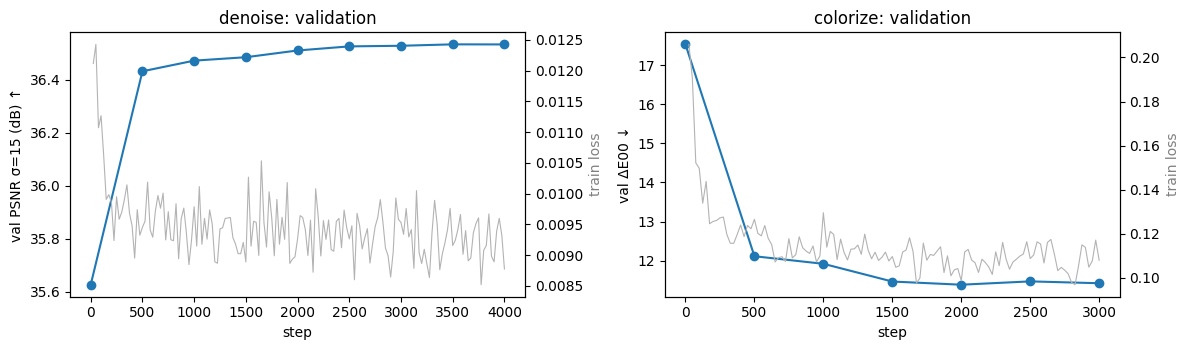

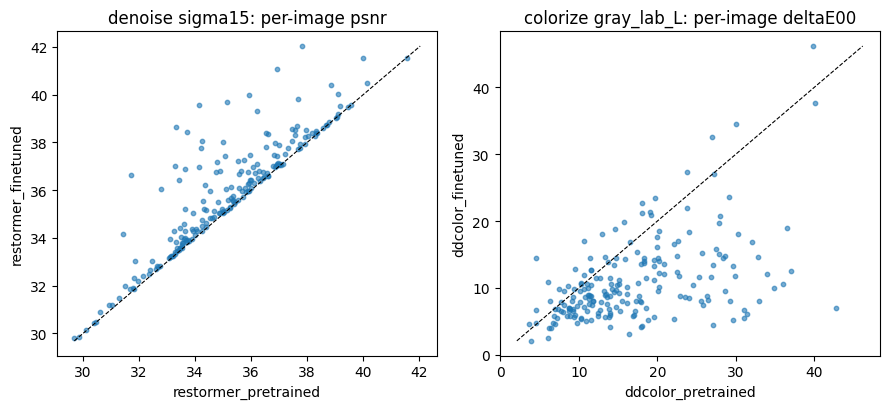

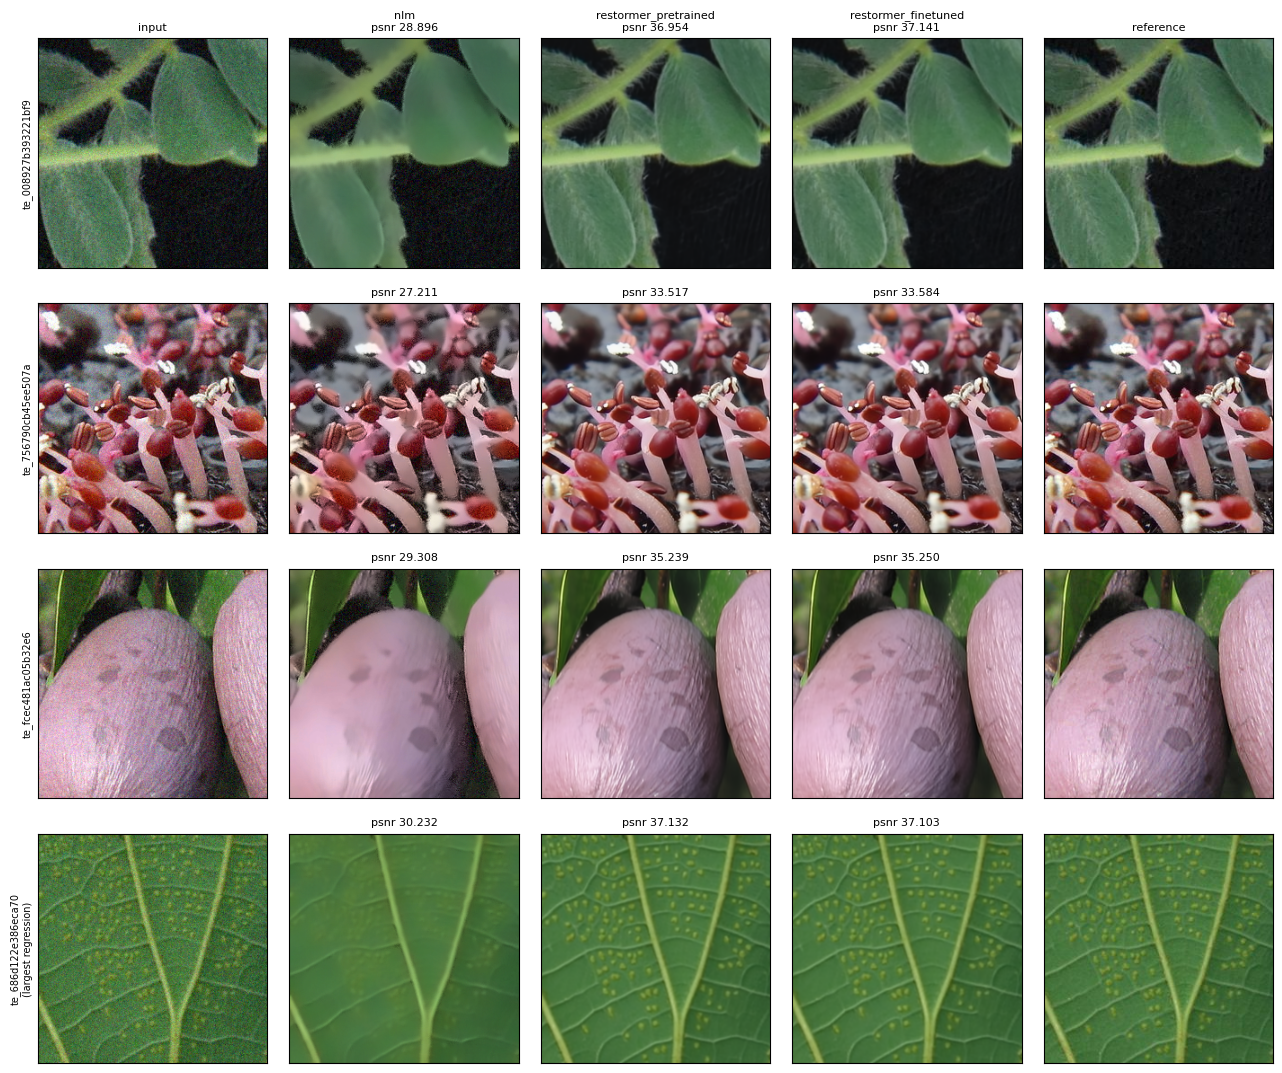

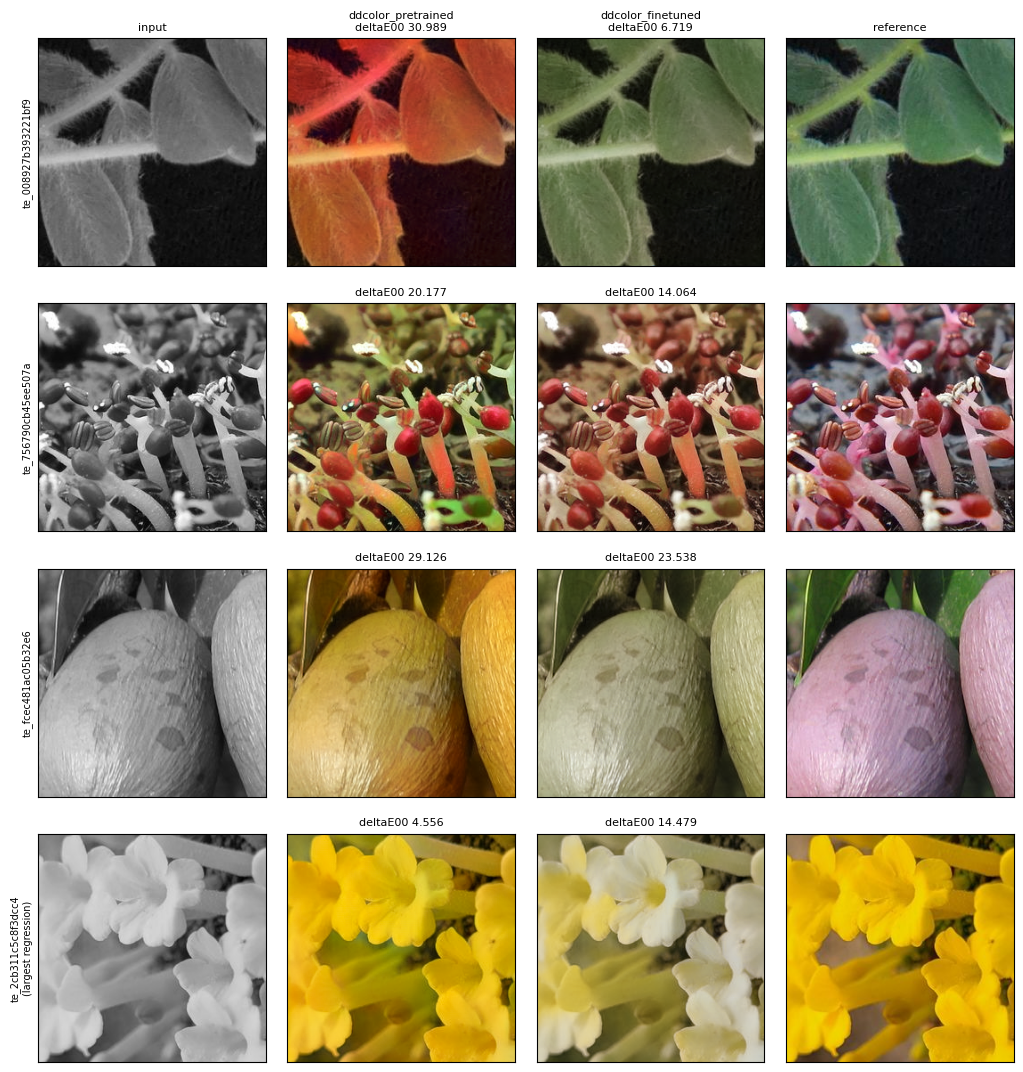

Figures saved to /content/drive/MyDrive/AAI521/Final_project/experiments/denoise_colorize/results/v1/figures


In [13]:
# Plot validation curves, per-image pretrained-vs-finetuned scatter, and visual comparison grids.
import matplotlib.pyplot as plt

FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

curves = [(t, lg, lbl) for t, lg, lbl, on in [("denoise", globals().get("DN_LOG"), "val PSNR σ=15 (dB) ↑", RUN_DENOISE),
                                              ("colorize", globals().get("CZ_LOG"), "val ΔE00 ↓", RUN_COLORIZE)] if on]
fig, axes = plt.subplots(1, len(curves), figsize=(6 * len(curves), 3.6), squeeze=False)
for ax, (task, log, label) in zip(axes[0], curves):
    v = log.dropna(subset=["val"])
    ax.plot(v["step"], v["val"], "o-")
    ax.set(title=f"{task}: validation", xlabel="step", ylabel=label)
    ax2 = ax.twinx()
    t = log.dropna(subset=["loss"])
    ax2.plot(t["step"], t["loss"], color="0.7", lw=0.8)
    ax2.set_ylabel("train loss", color="0.5")
fig.tight_layout()
fig.savefig(FIG_DIR / "training_curves.png", dpi=150)
plt.show()

scatter = [("denoise", f"sigma{DENOISE_CFG['test_sigmas'][0]}", "psnr")] if RUN_DENOISE else []
scatter += [("colorize", "gray_lab_L", "deltaE00")] if RUN_COLORIZE else []
fig, axes = plt.subplots(1, len(scatter), figsize=(4.5 * len(scatter), 4.2), squeeze=False)
for ax, (task, cond, metric) in zip(axes[0], scatter):
    before, after = PAIRS[task]
    w = ok[(ok.task == task) & (ok.condition == cond) & (ok.metric_name == metric)].pivot(
        index="sample_id", columns="method", values="metric_value")
    ax.scatter(w[before], w[after], s=10, alpha=0.6)
    lims = [min(w[before].min(), w[after].min()), max(w[before].max(), w[after].max())]
    ax.plot(lims, lims, "k--", lw=0.8)
    ax.set(title=f"{task} {cond}: per-image {metric}", xlabel=before, ylabel=after)
fig.tight_layout()
fig.savefig(FIG_DIR / "per_image_scatter.png", dpi=150)
plt.show()


def visual_grid(task, cond, methods, inputs, metric, higher_better, fname):
    w = ok[(ok.task == task) & (ok.condition == cond) & (ok.metric_name == metric)].pivot(
        index="sample_id", columns="method", values="metric_value")
    before, after = PAIRS[task]
    delta = (w[after] - w[before]) * (1 if higher_better else -1)
    order = sorted(test_ids)
    picks = [order[int(q * (len(order) - 1))] for q in (0.0, 0.5, 1.0)]
    worst = delta.idxmin()
    picks = [p for p in picks if p != worst] + [worst]
    cols = ["input"] + methods + ["reference"]
    fig, axes = plt.subplots(len(picks), len(cols), figsize=(2.6 * len(cols), 2.7 * len(picks)), squeeze=False)
    for r, sid in enumerate(picks):
        i = test_ids.index(sid)
        images = [inputs[i]] + [TEST_OUTPUTS[(task, cond, m)][i] for m in methods] + [test_clean[i]]
        for c, (name, img) in enumerate(zip(cols, images)):
            ax = axes[r, c]
            ax.imshow(img)
            ax.set_xticks([]), ax.set_yticks([])
            title = name if r == 0 else ""
            if name in w.columns:
                title += f"\n{metric} {w.loc[sid, name]:.3f}"
            ax.set_title(title, fontsize=8)
        axes[r, 0].set_ylabel(sid + ("\n(largest regression)" if sid == worst else ""), fontsize=7)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=130)
    plt.show()


if RUN_DENOISE:
    cond = f"sigma{DENOISE_CFG['test_sigmas'][0]}"
    visual_grid("denoise", cond, ["nlm", "restormer_pretrained", "restormer_finetuned"],
                EVAL_INPUTS[("denoise", cond, "test")], "psnr", True, f"grid_denoise_{cond}.png")
if RUN_COLORIZE:
    visual_grid("colorize", "gray_lab_L", ["ddcolor_pretrained", "ddcolor_finetuned"],
                EVAL_INPUTS[("colorize", "gray_lab_L", "test")], "deltaE00", False, "grid_colorize.png")
print(f"Figures saved to {FIG_DIR}")

## 12 · Inference wrapper for the shared app interface

`restore(image, task, mask=None, seed=42)` follows the interface in README §8. It returns:
- the output image
- the model version
- the processed dimensions
- the elapsed time
- success or error information

Denoising works at native resolution, with reflect padding to a multiple of 8. Colorization uses the official DDColor pipeline: the colour is predicted at 512 × 512 and combined with the input's full-resolution L\*. Both models are deterministic, so `seed` is accepted for interface compatibility but has no effect.

Large images can exceed GPU memory. If they do, the app should downscale them or split them into tiles.

In [14]:
# Shared restore() wrapper using the fine-tuned checkpoints, demonstrated on one test crop.
def restore(image, task, mask=None, seed=42):
    t0 = time.perf_counter()
    rgb = np.asarray(image.convert("RGB"), dtype=np.uint8)
    try:
        if task == "denoise":
            out, version = run_denoiser(dn_finetuned, rgb[None], batch=1)[0], f"{DN_REV}+ft:{RUN_TAG}"
        elif task == "colorize":
            gray = to_gray_u8(rgb[None])
            out = run_colorizer(cz_finetuned, gray, COLOR_CFG["input_size"], batch=1)[0]
            version = f"{CZ_REV}+ft:{RUN_TAG}"
        else:
            raise ValueError(f"This notebook provides 'denoise' and 'colorize', not {task!r}")
        return dict(image=Image.fromarray(out), task=task, model_version=version, size=out.shape[1::-1],
                    elapsed_seconds=time.perf_counter() - t0, ok=True, error=None)
    except Exception as exc:
        return dict(image=None, task=task, model_version=None, size=rgb.shape[1::-1],
                    elapsed_seconds=time.perf_counter() - t0, ok=False, error=repr(exc))


demos = {"denoise": EVAL_INPUTS[("denoise", f"sigma{DENOISE_CFG['test_sigmas'][0]}", "test")][0],
         "colorize": test_clean[0]}   # colorize converts any RGB upload to grayscale first
for task, enabled in (("denoise", RUN_DENOISE), ("colorize", RUN_COLORIZE)):
    if enabled:
        r = restore(Image.fromarray(demos[task]), task)
        print({k: v for k, v in r.items() if k != "image"})

{'task': 'denoise', 'model_version': 'deepinv/Restormer@aa2667c79d76+ft:v1', 'size': (256, 256), 'elapsed_seconds': 0.02786098900014622, 'ok': True, 'error': None}
{'task': 'colorize', 'model_version': 'piddnad/ddcolor_paper_tiny@cf9fd99c1d74+ft:v1', 'size': (256, 256), 'elapsed_seconds': 0.014715839999553282, 'ok': True, 'error': None}
